# W1 · Initial inspection of FONASA GRD data 2023-2024 (candidates A and B)
Business Intelligence IIB423T-1 · GROUP_López_Ramírez · version 1.1 (25-09-2026)

**Purpose.** Establish what each row of FONASA's public GRD (Diagnosis-Related Groups) files represents, its coverage and first quality checks, and produce a first summary for each candidate line:

- **Candidate A**: hospitalisation outside the patient's region of residence (inter-regional flow) in GRD-funded hospitals.
- **Candidate B**: case-mix-adjusted length of stay (GRD) and extreme stays (upper outliers) by hospital.

**Run order.** `analysis/01_extraer_grd.py` (run on the official .zip/.txt files; produced `data/extracted/*.csv.gz`) → this notebook top to bottom. All paths are relative to the `analysis/` folder.

**Inputs.** `data/extracted/grd_2023_extracto.csv.gz`, `data/extracted/grd_2024_extracto.csv.gz` (uncleaned extracts), `data/reference/Tablas_maestras_bases_GRD.xlsx` (FONASA dictionary), `data/reference/establecimientos_datosgobcl.csv` (MINSAL health facilities, datos.gob.cl).
**Outputs.** Tables in `data/processed/` and figures in `data/figures/`.

**Note on names.** File names are kept from the first version. Column names and category values are kept exactly as published by FONASA/MINSAL (in Spanish) so they can be traced to the official dictionaries. Key terms: *COMUNA* = municipality of residence, *COD_HOSPITAL* = DEIS facility code, *FECHA_INGRESO/FECHAALTA* = admission/discharge date, *TIPO_ACTIVIDAD* = episode type (HOSPITALIZACIÓN = inpatient stay, CMA = major ambulatory surgery), *TIPO_INGRESO* = admission type (URGENCIA = emergency, PROGRAMADA = elective, OBSTETRICA = obstetric), *IR_29301_PESO / SEVERIDAD* = GRD relative weight / severity level.

In [1]:
import hashlib, unicodedata, sys, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

BASE = Path("..")
EXT, REF = BASE/"data/extracted", BASE/"data/reference"
OUT, FIG = BASE/"data/processed", BASE/"data/figures"
OUT.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

# Palette (dataviz skill, categorical slots 1 and 2) and a restrained style
BLUE, ORANGE, INK, INK2 = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.6,
                     "axes.axisbelow": True})
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__, "| matplotlib", matplotlib.__version__, "|", platform.system())

def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
    return h.hexdigest()
for p in sorted(EXT.glob("*.gz")) + sorted(REF.glob("*")):
    print(f"{p.name:40s} {p.stat().st_size/1e6:7.1f} MB  sha256={sha256(p)[:16]}...")

def norm(s):
    # Upper case, no accents, trimmed: allows comparing labels coming from different sources
    s = s.fillna("").astype(str).str.upper().str.strip()
    return s.map(lambda x: "".join(c for c in unicodedata.normalize("NFKD", x) if not unicodedata.combining(c)))

Python 3.11.15 | pandas 3.0.2 | numpy 2.4.4 | matplotlib 3.10.9 | Linux


grd_2023_extracto.csv.gz                    40.2 MB  sha256=dbe960f33b218375...


grd_2024_extracto.csv.gz                    43.2 MB  sha256=7bb1f18b0a9817a5...
Tablas_maestras_bases_GRD.xlsx               0.1 MB  sha256=29da22ac27a79a5f...
establecimientos_datosgobcl.csv              2.5 MB  sha256=21c5965315280781...


## 1. Loading and unit of observation
The extracts keep the original values as text (no cleaning). The extraction only added `EDAD_ANIOS`, `N_DIAG`, `N_PROC` and `ANIO_BASE` (renamed on load to `AGE_YEARS`, `N_DIAGNOSES`, `N_PROCEDURES` and `BASE_YEAR`); it dropped the encrypted patient identifier and the date of birth (personal-data minimisation).

**What a row is.** According to the FONASA data catalogue, each record is an episode coded in the GRD tool by one of the GRD-funded hospitals: either an **inpatient discharge** or a **major ambulatory surgery (CMA)** (field `TIPO_ACTIVIDAD`). A row is not a patient: one person can contribute several episodes.

In [2]:
g = pd.concat([pd.read_csv(EXT/f"grd_{y}_extracto.csv.gz", dtype=str, keep_default_na=False) for y in (2023, 2024)],
              ignore_index=True)
# Derived columns were named in Spanish at extraction time; renamed here for readability
g = g.rename(columns={"EDAD_ANIOS": "AGE_YEARS", "N_DIAG": "N_DIAGNOSES", "N_PROC": "N_PROCEDURES", "ANIO_BASE": "BASE_YEAR"})
print("Rows:", f"{len(g):,}", "| columns:", g.shape[1])
print(g.columns.tolist())
g.head(3).T

Rows: 2,125,400 | columns: 26
['COD_HOSPITAL', 'SEXO', 'PROVINCIA', 'COMUNA', 'PREVISION', 'SERVICIO_SALUD', 'TIPO_PROCEDENCIA', 'TIPO_INGRESO', 'ESPECIALIDAD_MEDICA', 'TIPO_ACTIVIDAD', 'FECHA_INGRESO', 'SERVICIOINGRESO', 'FECHAALTA', 'SERVICIOALTA', 'TIPOALTA', 'DIAGNOSTICO1', 'USOSPABELLON', 'IR_29301_COD_GRD', 'IR_29301_PESO', 'IR_29301_SEVERIDAD', 'IR_29301_MORTALIDAD', 'HOSPPROCEDENCIA', 'N_DIAGNOSES', 'N_PROCEDURES', 'AGE_YEARS', 'BASE_YEAR']


,0,1,2
COD_HOSPITAL,122100,114101,114101
SEXO,HOMBRE,HOMBRE,HOMBRE
PROVINCIA,VALDIVIA,CORDILLERA,CORDILLERA
COMUNA,PANGUIPULLI,PUENTE ALTO,PUENTE ALTO
PREVISION,FONASA INSTITUCIONAL - (MAI) A,PARTICULAR,FONASA INSTITUCIONAL - (MAI) A
SERVICIO_SALUD,VALDIVIA,METROPOLITANO SURORIENTE,METROPOLITANO SURORIENTE
TIPO_PROCEDENCIA,SERVICIO EMERGENCIA (DOMICILIO),SERVICIO EMERGENCIA (DOMICILIO),"APS URGENCIA (SAPU, SUR, SUC)"
TIPO_INGRESO,URGENCIA,URGENCIA,URGENCIA
ESPECIALIDAD_MEDICA,CIRUGÍA GENERAL,CIRUGÍA GENERAL,PEDIATRÍA
TIPO_ACTIVIDAD,HOSPITALIZACIÓN,HOSPITALIZACIÓN,HOSPITALIZACIÓN


In [3]:
# Observed date formats (checked directly on the original text)
for y in ("2023", "2024"):
    m = g.BASE_YEAR == y
    example = g.loc[m, "FECHA_INGRESO"].iloc[0]
    p_ddmm = g.loc[m, "FECHA_INGRESO"].str.match(r"^\d{2}-\d{2}-\d{4}$").mean()
    p_iso = g.loc[m, "FECHA_INGRESO"].str.match(r"^\d{4}-\d{2}-\d{2}$").mean()
    print(f"{y}: example={example!r}  DD-MM-YYYY={p_ddmm:.4f}  YYYY-MM-DD={p_iso:.4f}")

FMT = {"2023": "%d-%m-%Y", "2024": "%Y-%m-%d"}
for c in ["FECHA_INGRESO", "FECHAALTA"]:
    g[c + "_DT"] = pd.NaT
    for y, f in FMT.items():
        m = g.BASE_YEAR == y
        g.loc[m, c + "_DT"] = pd.to_datetime(g.loc[m, c], format=f, errors="coerce")
    g[c + "_DT"] = pd.to_datetime(g[c + "_DT"])
g["LOS_DAYS"] = (g.FECHAALTA_DT - g.FECHA_INGRESO_DT).dt.days          # length of stay
g["WEIGHT"] = pd.to_numeric(g.IR_29301_PESO.str.replace(",", ".", regex=False), errors="coerce")
g["AGE"] = pd.to_numeric(g.AGE_YEARS, errors="coerce")

2023: example='12-03-2023'  DD-MM-YYYY=1.0000  YYYY-MM-DD=0.0000


2024: example='2024-03-23'  DD-MM-YYYY=0.0000  YYYY-MM-DD=1.0000


In [4]:
cov = (g.groupby("BASE_YEAR")
         .agg(episodes=("COD_HOSPITAL", "size"), hospitals=("COD_HOSPITAL", "nunique"),
              discharge_min=("FECHAALTA_DT", "min"), discharge_max=("FECHAALTA_DT", "max"),
              admission_min=("FECHA_INGRESO_DT", "min"),
              municipalities_of_residence=("COMUNA", "nunique")))
act = pd.crosstab(g.BASE_YEAR, g.TIPO_ACTIVIDAD).rename(columns={"HOSPITALIZACIÓN": "inpatient", "CIRUGÍA MAYOR AMBULATORIA (CMA)": "ambulatory_surgery_CMA"})
cov = cov.join(act)
cov.to_csv(OUT/"t01_cobertura.csv")
cov

,episodes,hospitals,discharge_min,discharge_max,admission_min,municipalities_of_residence,ambulatory_surgery_CMA,inpatient
BASE_YEAR,,,,,,,,
2023,1039587,68,2023-01-01,2023-12-31,2022-01-07,347,193544,846043
2024,1085813,72,2024-01-01,2024-12-31,2023-01-01,344,212041,873772


In [5]:
# Hospitals present in only one year (a coverage change, not an activity change)
hy = g.groupby(["COD_HOSPITAL", "BASE_YEAR"]).size().unstack()
only_one = hy[hy.isna().any(axis=1)]
fac = pd.read_csv(REF/"establecimientos_datosgobcl.csv", sep=";", dtype=str)
names = fac.set_index("EstablecimientoCodigo")["EstablecimientoGlosa"]
only_one.assign(name=only_one.index.map(names))

BASE_YEAR,2023,2024,name
COD_HOSPITAL,,,
116107,NaN,3204.0,Hospital de Constitución
116111,NaN,4682.0,Hospital San Juan de Dios (Cauquenes)
119102,NaN,4157.0,Hospital Penco Lirquén
200717,NaN,10354.0,Complejo Asistencial Padre las Casas


**Reading.** The files are organised by **discharge year**: every discharge in `GRD_PUBLICO_2023` falls in 2023 and every discharge in 2024 falls in 2024 (admission can be earlier). There are 68 hospitals in 2023 and 72 in 2024: four facilities join in 2024. Any comparison between years must therefore be restricted to the 68 common hospitals; otherwise the increase in episodes would mix a coverage change with an activity change.

## 2. First quality checks (Five Cs)
We use an operational reading of the Five Cs: **completeness**, **consistency**, **conformity** (domain/format), **coverage/currency** and **credibility/traceability**. If the definition presented in class differs, this table is re-labelled but the checks stay the same.

In [6]:
dic = pd.read_excel(REF/"Tablas_maestras_bases_GRD.xlsx", sheet_name="IR - GRD", header=None, skiprows=1, dtype=str)
dic.columns = ["CODE", "DESCRIPTION"]; dic["CODE6"] = dic.CODE.str.strip().str.zfill(6)
inpatient = g.TIPO_ACTIVIDAD == "HOSPITALIZACIÓN"
checks = [
 ("Completeness", "FECHA_INGRESO (admission date) not parseable", g.FECHA_INGRESO_DT.isna().sum()),
 ("Completeness", "FECHAALTA (discharge date) not parseable", g.FECHAALTA_DT.isna().sum()),
 ("Completeness", "COMUNA = 'DESCONOCIDO' (unknown) or empty", g.COMUNA.isin(["", "DESCONOCIDO"]).sum()),
 ("Completeness", "Age not computable", g.AGE.isna().sum()),
 ("Completeness", "HOSPPROCEDENCIA empty (expected: only transfers have it)", (g.HOSPPROCEDENCIA == "").sum()),
 ("Consistency", "Negative length of stay (discharge < admission)", (g.LOS_DAYS < 0).sum()),
 ("Consistency", "CMA with length of stay > 1 day", ((~inpatient) & (g.LOS_DAYS > 1)).sum()),
 ("Consistency", "Age < 0 or > 110", ((g.AGE < 0) | (g.AGE > 110)).sum()),
 ("Conformity", "GRD code not in the IR-GRD dictionary", (~g.IR_29301_COD_GRD.isin(dic.CODE6)).sum()),
 ("Conformity", "GRD weight not numeric", g.WEIGHT.isna().sum()),
 ("Conformity", "Severity outside {0,1,2,3}", (~g.IR_29301_SEVERIDAD.isin(list("0123"))).sum()),
 ("Coverage", "Hospitals 2023 / 2024", f"{g[g.BASE_YEAR=='2023'].COD_HOSPITAL.nunique()} / {g[g.BASE_YEAR=='2024'].COD_HOSPITAL.nunique()}"),
 ("Credibility", "FONASA extraction date 2023 / 2024", "04-09-2024 / 16-05-2025 (FONASA catalogue)"),
]
qc = pd.DataFrame(checks, columns=["C", "check", "result"])
qc["pct_of_episodes"] = [f"{v/len(g):.4%}" if isinstance(v, (int, np.integer)) else "" for v in qc.result]
qc.to_csv(OUT/"t02_five_cs.csv", index=False)
qc

,C,check,result,pct_of_episodes
0,Completeness,FECHA_INGRESO (admission date) not parseable,52,0.0024%
1,Completeness,FECHAALTA (discharge date) not parseable,0,0.0000%
2,Completeness,COMUNA = 'DESCONOCIDO' (unknown) or empty,12,0.0006%
3,Completeness,Age not computable,65,0.0031%
4,Completeness,HOSPPROCEDENCIA empty (expected: only transfer...,1892677,89.0504%
5,Consistency,Negative length of stay (discharge < admission),0,0.0000%
6,Consistency,CMA with length of stay > 1 day,419,0.0197%
7,Consistency,Age < 0 or > 110,0,0.0000%
8,Conformity,GRD code not in the IR-GRD dictionary,47,0.0022%
9,Conformity,GRD weight not numeric,45,0.0021%


In [7]:
# Schema differences between years found during extraction (consistency across versions)
schema = pd.DataFrame({
  "aspect": ["File encoding", "Patient identifier column", "Admission/discharge date format",
             "Date-of-birth format", "Decimal separator of GRD weight"],
  "2023": ["UTF-16", "CIP_ENCRIPTADO", "DD-MM-YYYY", "YYYY-MM-DD", "comma"],
  "2024": ["Latin-1", "ID_BENEFICIARIO", "YYYY-MM-DD", "YYYY-MM-DD", "comma"]})
schema.to_csv(OUT/"t03_esquema_por_anio.csv", index=False)
schema

,aspect,2023,2024
0,File encoding,UTF-16,Latin-1
1,Patient identifier column,CIP_ENCRIPTADO,ID_BENEFICIARIO
2,Admission/discharge date format,DD-MM-YYYY,YYYY-MM-DD
3,Date-of-birth format,YYYY-MM-DD,YYYY-MM-DD
4,Decimal separator of GRD weight,comma,comma


**Reading.** The fields the candidates need (hospital, municipality of residence, dates, GRD, weight and severity) are practically complete. The relevant problems are **consistency across versions** (different encoding and date format per year) and **coverage** (68 vs 72 hospitals). 45 episodes have GRD `DESCONOCIDO` (unknown) and 2 codes are not in the dictionary; they are excluded from B.

## 3. Checking the reference repository (Group 5, `proyecto-GRD-Fonasa`)
We reviewed the public repository used as a starting point to decide what to adopt. Three of its assumptions were tested against the data:

In [8]:
# (a) Date format used by the reference: date_format="%d/%m/%Y" for both years
for y in ("2023", "2024"):
    m = g.BASE_YEAR == y
    ok = pd.to_datetime(g.loc[m, "FECHA_INGRESO"], format="%d/%m/%Y", errors="coerce").notna().mean()
    print(f"{y}: % of FECHA_INGRESO parseable with '%d/%m/%Y' = {ok:.2%}")

# (b) Does SERVICIO_SALUD describe the hospital or the patient? Distinct health services per hospital
ss_per_hosp = g.groupby("COD_HOSPITAL").SERVICIO_SALUD.nunique()
print("Distinct health services per hospital: median", ss_per_hosp.median(), "| max", ss_per_hosp.max())

# (c) Ambulatory surgery (CMA) mixed with inpatient stays
print("Share of CMA episodes in the files:", f"{(~inpatient).mean():.1%}")

2023: % of FECHA_INGRESO parseable with '%d/%m/%Y' = 0.00%
2024: % of FECHA_INGRESO parseable with '%d/%m/%Y' = 0.00%


Distinct health services per hospital: median 18.5 | max 30
Share of CMA episodes in the files: 19.1%


**Decisions.** (a) The reference's declared date format matches neither year. This is consistent with the length of stay it reports (only 211,157 valid stays, mean 110.9 days, against about 7 days when recomputed). We recompute stays with each year's observed format. (b) Each hospital records up to 30 different health services, so `SERVICIO_SALUD` describes the **patient's health service**, not the hospital's; we do not use it to locate the hospital. (c) CMA episodes (≈19%) have no stay, so A and B are computed on `HOSPITALIZACIÓN` (inpatient) episodes only. The reference also defined a "non-local by municipality" patient (48.6%). In high-complexity hospitals, treating patients from other municipalities is expected by network design, so we use the **region** of residence, derived from the municipality rather than from the modal region of the province.

## 4. Candidate A: hospitalisation outside the region of residence
**Joins.** (1) `COD_HOSPITAL` → `EstablecimientoCodigo` (MINSAL facilities) to obtain the hospital's region and complexity level: **verified**, 72 of 72 hospitals match. (2) Municipality of residence (text) → region, through a municipality-region table built from the same facilities file (mode per municipality, normalised labels): **proposed and tested**; 0.0006% of episodes remain without a region. A shared key does not guarantee the same meaning: the hospital's region comes from the current version of the facilities file, while the patient's municipality is the one recorded in the episode.

In [9]:
fac["REG"] = norm(fac.RegionGlosa); fac["MUN"] = norm(fac.ComunaGlosa)
# Municipality-region conflicts in the source (capitalisation 'De'/'de' and 2 mis-assigned municipalities) -> mode
conf = fac.groupby("MUN").REG.nunique(); print("Municipalities with >1 region after normalising:", (conf > 1).sum(), list(conf[conf > 1].index))
mun2reg = fac.groupby("MUN").REG.agg(lambda x: x.mode()[0])
alias = {"COIHAIQUE": "COYHAIQUE", 'O"HIGGINS': "O'HIGGINS", "ANTARTICA": "CABO DE HORNOS"}  # GRD spelling -> MINSAL spelling
g["REG_RES"] = norm(g.COMUNA).replace(alias).map(mun2reg)
hosp_info = fac.set_index("EstablecimientoCodigo")[["REG", "NivelComplejidadEstabGlosa", "EstablecimientoGlosa"]]
hosp_info.columns = ["REG_HOSP", "COMPLEXITY", "HOSPITAL"]
g = g.join(hosp_info, on="COD_HOSPITAL")
print("Hospitals without match:", g.REG_HOSP.isna().sum(), "| episodes without region of residence:", g.REG_RES.isna().sum())
print(g.drop_duplicates("COD_HOSPITAL").COMPLEXITY.value_counts())

Municipalities with >1 region after normalising: 2 ['LONGAVI', 'TUCAPEL']


Hospitals without match: 0 | episodes without region of residence: 12
COMPLEXITY
Alta Complejidad       58
Mediana Complejidad    14
Name: count, dtype: int64


In [10]:
H = g[inpatient & g.REG_RES.notna()].copy()
common = hy.dropna().index                       # 68 hospitals present in both years
H = H[H.COD_HOSPITAL.isin(common)]
H["OUTSIDE"] = H.REG_RES != H.REG_HOSP
REGION_NAME = {"REGION DE ARICA PARINACOTA": "Arica y Parinacota", "REGION DE TARAPACA": "Tarapacá",
  "REGION DE ANTOFAGASTA": "Antofagasta", "REGION DE ATACAMA": "Atacama", "REGION DE COQUIMBO": "Coquimbo",
  "REGION DE VALPARAISO": "Valparaíso", "REGION METROPOLITANA DE SANTIAGO": "Metropolitan (Santiago)",
  "REGION DEL LIBERTADOR GRAL. B. O'HIGGINS": "O'Higgins", "REGION DEL MAULE": "Maule", "REGION DE NUBLE": "Ñuble",
  "REGION DEL BIOBIO": "Biobío", "REGION DE LA ARAUCANIA": "La Araucanía", "REGION DE LOS RIOS": "Los Ríos",
  "REGION DE LOS LAGOS": "Los Lagos", "REGION DE AYSEN DEL GENERAL CARLOS IBANEZ DEL CAMPO": "Aysén",
  "REGION DE MAGALLANES Y DE LA ANTARTICA CHILENA": "Magallanes"}
H["RES_REGION"], H["HOSP_REGION"] = H.REG_RES.map(REGION_NAME), H.REG_HOSP.map(REGION_NAME)
tA = (H.groupby(["RES_REGION", "BASE_YEAR"]).OUTSIDE.agg(n="size", outside="sum", pct="mean").unstack())
tA.columns = [f"{a}_{b}" for a, b in tA.columns]
tA = tA.sort_values("pct_2024", ascending=False)
tA.to_csv(OUT/"tA1_fuera_region_por_region_residencia.csv")
print("Total outside region of residence (68 common hospitals):", H.groupby("BASE_YEAR").OUTSIDE.mean().round(4).to_dict())
tA.style.format({c: "{:.1%}" for c in tA.columns if c.startswith("pct")} | {c: "{:,.0f}" for c in tA.columns if not c.startswith("pct")})

Total outside region of residence (68 common hospitals): {'2023': 0.0235, '2024': 0.0228}


,n_2023,n_2024,outside_2023,outside_2024,pct_2023,pct_2024
RES_REGION,,,,,,
O'Higgins,"34,685","35,593","2,044","2,131",5.9%,6.0%
Aysén,"9,181","9,434",503,564,5.5%,6.0%
Los Ríos,"19,868","19,872","1,387","1,159",7.0%,5.8%
Atacama,"17,856","17,719","1,006","1,019",5.6%,5.8%
Ñuble,"25,932","28,270","1,187","1,351",4.6%,4.8%
Tarapacá,"18,477","18,391",770,807,4.2%,4.4%
Coquimbo,"38,619","37,920","1,228","1,326",3.2%,3.5%
Los Lagos,"47,866","48,746","1,697","1,626",3.5%,3.3%
Arica y Parinacota,"16,840","17,301",497,563,3.0%,3.3%


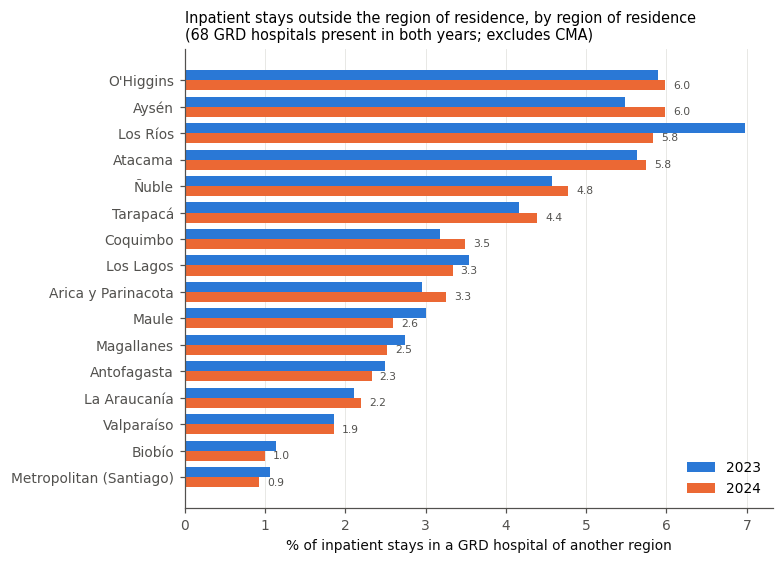

In [11]:
fig, ax = plt.subplots(figsize=(7.2, 5.2))
order = tA.index[::-1]; y = np.arange(len(order)); h = 0.38
ax.barh(y + h/2, tA.loc[order, "pct_2023"]*100, height=h, color=BLUE, label="2023")
ax.barh(y - h/2, tA.loc[order, "pct_2024"]*100, height=h, color=ORANGE, label="2024")
ax.set_yticks(y, order); ax.set_xlabel("% of inpatient stays in a GRD hospital of another region")
ax.set_title("Inpatient stays outside the region of residence, by region of residence\n(68 GRD hospitals present in both years; excludes CMA)", fontsize=9.5, loc="left")
ax.grid(axis="y", visible=False); ax.legend(frameon=False, loc="lower right")
for yi, v in zip(y, tA.loc[order, "pct_2024"]*100): ax.text(v + 0.1, yi - h/2, f"{v:.1f}", va="center", fontsize=7, color=INK2)
fig.tight_layout(); fig.savefig(FIG/"figA1_fuera_region.png"); plt.show()

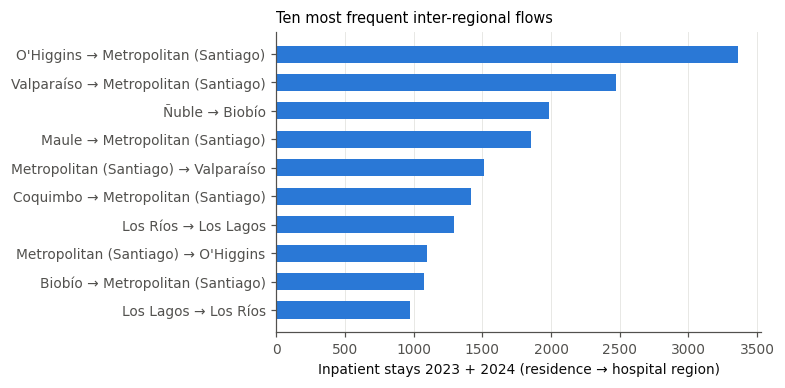

,RES_REGION,HOSP_REGION,episodes_2023_2024,flow
0,O'Higgins,Metropolitan (Santiago),3364,O'Higgins → Metropolitan (Santiago)
1,Valparaíso,Metropolitan (Santiago),2473,Valparaíso → Metropolitan (Santiago)
2,Ñuble,Biobío,1987,Ñuble → Biobío
3,Maule,Metropolitan (Santiago),1852,Maule → Metropolitan (Santiago)
4,Metropolitan (Santiago),Valparaíso,1510,Metropolitan (Santiago) → Valparaíso
5,Coquimbo,Metropolitan (Santiago),1420,Coquimbo → Metropolitan (Santiago)
6,Los Ríos,Los Lagos,1293,Los Ríos → Los Lagos
7,Metropolitan (Santiago),O'Higgins,1095,Metropolitan (Santiago) → O'Higgins
8,Biobío,Metropolitan (Santiago),1076,Biobío → Metropolitan (Santiago)
9,Los Lagos,Los Ríos,973,Los Lagos → Los Ríos


In [12]:
flows = (H[H.OUTSIDE].groupby(["RES_REGION", "HOSP_REGION"]).size().sort_values(ascending=False).head(10)
           .rename("episodes_2023_2024").reset_index())
flows["flow"] = flows.RES_REGION + " → " + flows.HOSP_REGION
flows.to_csv(OUT/"tA2_top_flujos.csv", index=False)
fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.barh(flows.flow[::-1], flows.episodes_2023_2024[::-1], color=BLUE, height=0.6)
ax.set_xlabel("Inpatient stays 2023 + 2024 (residence → hospital region)")
ax.set_title("Ten most frequent inter-regional flows", fontsize=9.5, loc="left"); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(FIG/"figA2_top_flujos.png"); plt.show()
flows

In [13]:
# Is it concentrated in more complex cases? By GRD-weight quartile and by admission type
H["WEIGHT_QUARTILE"] = pd.qcut(H.WEIGHT, 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
ADM = {"URGENCIA": "Emergency", "PROGRAMADA": "Elective", "OBSTETRICA": "Obstetric"}
tA3 = pd.concat({"by GRD weight quartile": H.groupby("WEIGHT_QUARTILE", observed=True).OUTSIDE.mean(),
                 "by admission type": H[H.TIPO_INGRESO.isin(ADM)].groupby(H.TIPO_INGRESO.map(ADM)).OUTSIDE.mean()})
tA3.rename("pct_outside_region").to_frame().to_csv(OUT/"tA3_fuera_region_por_complejidad.csv")
tA3.map("{:.1%}".format).to_frame("% outside region")

% outside region
by GRD weight quartile Q1 (lowest)              1.2%
                       Q2                       2.0%
                       Q3                       2.0%
                       Q4 (highest)             4.1%
by admission type      Elective                 4.7%
                       Emergency                1.9%
                       Obstetric                0.9%

**First reading of A.** In the 68 common hospitals, about 2.3% of inpatient stays take place outside the patient's region of residence, but the share varies widely between regions: O'Higgins, Aysén, Los Ríos and Atacama exceed 5%, while the Metropolitan region and Biobío are close to 1%. The Metropolitan region is the main destination. The share rises with GRD weight (Q4 ≈ 4.1% vs Q1 ≈ 1.2%) and is higher for elective admissions (4.7%) than for emergency admissions (1.9%). This suggests that referral concentrates on complex, elective cases.
**Limitation.** The denominator is inpatient stays in GRD hospitals only: a resident treated in a non-GRD hospital or a private clinic does not appear. The indicator therefore **does not measure population access** or unmet need; it describes referral within the GRD network. It also cannot distinguish a referral from a patient who fell ill while travelling.

## 5. Candidate B: case-mix-adjusted length of stay and extreme stays
**Operational definitions (ours, not official).** Length of stay (LOS) = `FECHAALTA − FECHA_INGRESO` in days, inpatient episodes only. Upper outlier = LOS > Q3 + 1.5·IQR **within each GRD code** (2023+2024). Expected LOS of an episode = mean LOS of the non-outlier cases of its GRD. **IEMA** (case-mix-adjusted mean stay index) of a hospital = Σ observed LOS / Σ expected LOS over its non-outlier episodes (indirect standardisation; 1 = as expected for its case mix). The official MINSAL norm is not published with these files, so the benchmark is the observed set of GRD hospitals.

In [14]:
B = g[inpatient & g.LOS_DAYS.notna() & g.IR_29301_COD_GRD.isin(dic.CODE6)].copy()
print(f"Analysable inpatient stays: {len(B):,} | stays of 0 days: {(B.LOS_DAYS == 0).mean():.1%}")
desc = B.groupby("BASE_YEAR").LOS_DAYS.describe(percentiles=[.25, .5, .75, .9, .99]).round(2)
desc.to_csv(OUT/"tB1_estancia_descriptiva.csv"); desc

Analysable inpatient stays: 1,719,718 | stays of 0 days: 5.2%


,count,mean,std,min,25%,50%,75%,90%,99%,max
BASE_YEAR,,,,,,,,,,
2023,846013.0,7.10,13.34,0.0,2.0,3.0,7.0,16.0,58.0,696.0
2024,873705.0,7.05,13.15,0.0,2.0,3.0,7.0,16.0,57.0,661.0


In [15]:
q = B.groupby("IR_29301_COD_GRD").LOS_DAYS.quantile([.25, .75]).unstack()
q["THRESHOLD"] = q[.75] + 1.5*(q[.75] - q[.25])
B = B.join(q["THRESHOLD"], on="IR_29301_COD_GRD")
B["OUTLIER"] = B.LOS_DAYS > B.THRESHOLD
res = B.groupby("BASE_YEAR").apply(lambda d: pd.Series({
    "pct_episodes_outlier": d.OUTLIER.mean(),
    "pct_bed_days_in_outliers": d.loc[d.OUTLIER, "LOS_DAYS"].sum()/d.LOS_DAYS.sum(),
    "mean_los_outliers": d.loc[d.OUTLIER, "LOS_DAYS"].mean(),
    "mean_los_non_outliers": d.loc[~d.OUTLIER, "LOS_DAYS"].mean()}))
n_grd = B.groupby("IR_29301_COD_GRD").size()
print("Distinct GRDs:", len(n_grd), "| with < 30 episodes (unstable threshold):", (n_grd < 30).sum())
res.to_csv(OUT/"tB2_outliers.csv"); res.style.format({c: "{:.1%}" for c in res.columns[:2]} | {c: "{:.1f}" for c in res.columns[2:]})

Distinct GRDs: 790 | with < 30 episodes (unstable threshold): 33


,pct_episodes_outlier,pct_bed_days_in_outliers,mean_los_outliers,mean_los_non_outliers
BASE_YEAR,,,,
2023,6.7%,26.2%,28.0,5.6
2024,6.3%,25.4%,28.5,5.6


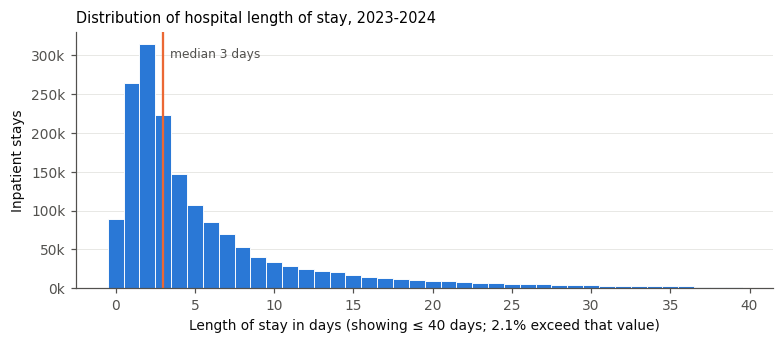

In [16]:
fig, ax = plt.subplots(figsize=(7.2, 3.2))
v = B.loc[B.LOS_DAYS <= 40, "LOS_DAYS"]
ax.hist(v, bins=np.arange(-0.5, 40.5, 1), color=BLUE, edgecolor="white", linewidth=0.6)
ax.axvline(B.LOS_DAYS.median(), color=ORANGE, lw=1.5); ax.text(B.LOS_DAYS.median() + 0.4, ax.get_ylim()[1]*0.9, f"median {B.LOS_DAYS.median():.0f} days", color=INK2, fontsize=8)
ax.set_xlabel("Length of stay in days (showing ≤ 40 days; " + f"{(B.LOS_DAYS > 40).mean():.1%} exceed that value)"); ax.set_ylabel("Inpatient stays")
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))
ax.set_title("Distribution of hospital length of stay, 2023-2024", fontsize=9.5, loc="left"); ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIG/"figB1_estancia.png"); plt.show()

In [17]:
I = B[~B.OUTLIER].copy()
I = I.join(I.groupby("IR_29301_COD_GRD").LOS_DAYS.mean().rename("EXPECTED_LOS"), on="IR_29301_COD_GRD")
r = (I.groupby(["COD_HOSPITAL", "BASE_YEAR"])
       .agg(n=("LOS_DAYS", "size"), observed=("LOS_DAYS", "sum"), expected=("EXPECTED_LOS", "sum"),
            crude_mean_los=("LOS_DAYS", "mean"), mean_weight=("WEIGHT", "mean")))
r["IEMA"] = r.observed / r.expected
r = r.join(B.groupby(["COD_HOSPITAL", "BASE_YEAR"]).OUTLIER.mean().rename("pct_outlier"))
r["HOSPITAL"] = r.index.get_level_values(0).map(names)
r.to_csv(OUT/"tB3_iema_por_hospital.csv")
w = r.IEMA.unstack().dropna()
print("Hospitals with IEMA in both years:", len(w), "| IEMA correlation 2023-2024:", round(w.corr().iloc[0, 1], 3))
print("% outlier correlation 2023-2024:", round(r.pct_outlier.unstack().dropna().corr().iloc[0, 1], 3))
print("Correlation across hospitals (2024): crude mean LOS vs mean weight =", round(r.xs("2024", level=1)[["crude_mean_los", "mean_weight"]].corr().iloc[0, 1], 3),
      "| IEMA vs mean weight =", round(r.xs("2024", level=1)[["IEMA", "mean_weight"]].corr().iloc[0, 1], 3))
r.xs("2024", level=1).sort_values("IEMA").iloc[np.r_[0:5, -5:0]][["HOSPITAL", "n", "crude_mean_los", "mean_weight", "IEMA", "pct_outlier"]].round(3)

Hospitals with IEMA in both years: 68 | IEMA correlation 2023-2024: 0.929
% outlier correlation 2023-2024: 0.9
Correlation across hospitals (2024): crude mean LOS vs mean weight = 0.534 | IEMA vs mean weight = -0.074


,HOSPITAL,n,crude_mean_los,mean_weight,IEMA,pct_outlier
COD_HOSPITAL,,,,,,
110110,Instituto Traumatológico Dr. Teodoro Gebauer,2997,3.847,1.301,0.706,0.030
112104,Instituto de Neurocirugía Dr. Alfonso Asenjo,3503,5.793,1.922,0.712,0.016
116107,Hospital de Constitución,2716,3.669,0.692,0.716,0.029
125100,Hospital Regional de Coyhaique,8686,3.952,0.942,0.744,0.028
114101,Complejo Hospitalario Dr. Sótero del Río (Sant...,37731,4.701,1.206,0.786,0.037
129106,Hospital San José de Victoria,6583,5.201,0.863,1.116,0.063
109100,"Complejo Hospitalario San José (Santiago, Inde...",18510,6.260,1.028,1.138,0.099
103100,Hospital Dr. Leonardo Guzmán (Antofagasta),18074,6.459,1.089,1.143,0.097
106102,Hospital Dr. Eduardo Pereira Ramírez (Valparaíso),3997,8.381,1.348,1.162,0.073


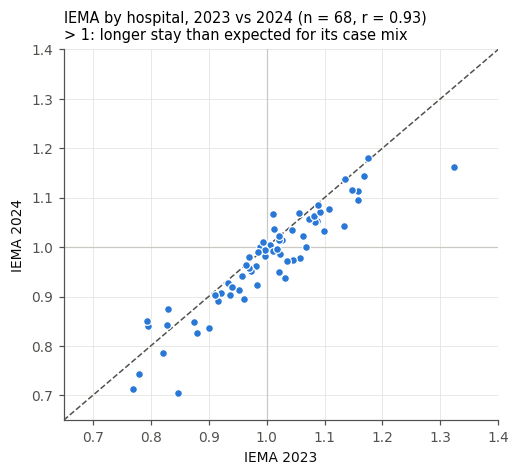

In [18]:
fig, ax = plt.subplots(figsize=(4.8, 4.4))
ax.scatter(w["2023"], w["2024"], s=26, color=BLUE, edgecolor="white", linewidth=0.8, zorder=3)
lim = [0.65, 1.4]; ax.plot(lim, lim, color=INK2, lw=1, ls="--"); ax.axhline(1, color="#c9c8c3", lw=0.8); ax.axvline(1, color="#c9c8c3", lw=0.8)
ax.set_xlim(lim); ax.set_ylim(lim); ax.set_xlabel("IEMA 2023"); ax.set_ylabel("IEMA 2024")
ax.set_title(f"IEMA by hospital, 2023 vs 2024 (n = {len(w)}, r = {w.corr().iloc[0,1]:.2f})\n> 1: longer stay than expected for its case mix", fontsize=9.5, loc="left")
fig.tight_layout(); fig.savefig(FIG/"figB2_iema_2023_2024.png"); plt.show()

**First reading of B.** Median LOS is 3 days and mean LOS about 7, with a long tail (P99 ≈ 58 days). Upper outliers are 6.3-6.7% of inpatient stays but account for 25-26% of bed-days (mean LOS ≈ 28 days vs ≈ 5.6 for the rest). IEMA varies between hospitals (roughly 0.7 to 1.3) and is **stable between 2023 and 2024** (r ≈ 0.93), which indicates a persistent signal rather than year-to-year noise. Case-mix adjustment changes the ranking: crude mean LOS correlates with a hospital's mean GRD weight, while IEMA hardly does.
**Limitations.** The benchmark is the set of GRD hospitals, not an external norm. Some GRDs have few cases (unstable threshold). LOS includes internal transfers, and the files do not record bed-waiting time or social reasons for delayed discharge. A high IEMA may reflect complexity not captured by the GRD (for example, a national referral role).

In [19]:
# Summary of what was exported for the report and README
for p in sorted(OUT.glob("*.csv")) + sorted(FIG.glob("*.png")):
    print(p.relative_to(BASE))

data/processed/t01_cobertura.csv
data/processed/t02_five_cs.csv
data/processed/t03_esquema_por_anio.csv
data/processed/tA1_fuera_region_por_region_residencia.csv
data/processed/tA2_top_flujos.csv
data/processed/tA3_fuera_region_por_complejidad.csv
data/processed/tB1_estancia_descriptiva.csv
data/processed/tB2_outliers.csv
data/processed/tB3_iema_por_hospital.csv
data/figures/figA1_fuera_region.png
data/figures/figA2_top_flujos.png
data/figures/figB1_estancia.png
data/figures/figB2_iema_2023_2024.png
